# Simulator Demo

Walkthrough of the Simulator component: scanner ray sweeps, hard vs. soft-occlusion ray casting, the noise pipeline, the full `simulate()` forward model, visualisation, and sim-to-real noise calibration.

See `docs/simulator.md` for the full component specification.

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from representation.floor_plan import FloorPlanGraph
from simulator import calibration
from simulator import visualisation as sim_viz
from simulator.engine import DEFAULT_HEIGHTS, simulate
from simulator.noise_model import (
    NoiseModel,
    NoiseModelPrior,
    apply_clutter,
    apply_missing_returns,
    apply_range_noise,
    perturb_directions,
)
from simulator.ray_caster import cast_rays
from simulator.scanner import ScannerConfig, generate_rays

## Floor plan

The same two-room, 4m x 2m footprint used in the representation demo.

In [2]:
def build_two_room_floor_plan() -> FloorPlanGraph:
    graph = FloorPlanGraph()
    positions = [(0.0, 0.0), (2.0, 0.0), (4.0, 0.0), (4.0, 2.0), (2.0, 2.0), (0.0, 2.0)]
    j = [graph.add_junction(p) for p in positions]

    perimeter_pairs = [(0, 1), (1, 2), (2, 3), (3, 4), (4, 5), (5, 0)]
    for start, end in perimeter_pairs:
        graph.add_segment(j[start].id, j[end].id)

    graph.add_segment(j[1].id, j[4].id)  # dividing wall between the two rooms
    return graph


floor_plan = build_two_room_floor_plan()
scanner_positions = jnp.array([[1.0, 1.0], [3.0, 1.0]])  # one scanner per room
print(f"{len(floor_plan.junctions)} junctions, {len(floor_plan.segments)} segments")

6 junctions, 7 segments


## Scanner sweep

`ScannerConfig` defines the angular sweep and slice height; `generate_rays` turns a scanner position into ray origins and unit directions.

In [3]:
config = ScannerConfig(height=1.0, num_rays=16)
origins, directions = generate_rays(scanner_positions[0], config)

print("origins shape:", origins.shape, " directions shape:", directions.shape)
print("first 4 ray angles (degrees):", np.degrees(np.asarray(config.ray_angles()[:4])))

origins shape: (16, 2)  directions shape: (16, 2)
first 4 ray angles (degrees): [ 0.  22.5 45.  67.5]


## Ray casting: hard vs. soft occlusion

Hard occlusion returns the nearest wall via `argmin` (not differentiable); soft occlusion approximates it with a softmin over all intersections. The two should agree closely for a large `beta`.

In [5]:
segments = floor_plan.to_segment_array()
mask = floor_plan.segment_mask()

config = ScannerConfig(height=1.0, num_rays=360)
origins, directions = generate_rays(scanner_positions[0], config)

hard_distances, hard_hits, hard_points = cast_rays(origins, directions, segments, mask)
soft_distances, soft_hits, soft_points = cast_rays(
    origins, directions, segments, mask, differentiable=True, beta=100.0
)

print("all rays hit a wall (hard):", bool(jnp.all(hard_hits)))
print("max |hard - soft| distance:", float(jnp.max(jnp.abs(hard_distances - soft_distances))))

all rays hit a wall (hard): True
max |hard - soft| distance: 0.0003510713577270508


## Noise pipeline

Each stochastic step -- angular jitter, range noise, missing returns, clutter -- is an explicit `jax.random.PRNGKey` draw.

In [11]:
rng_key = jax.random.PRNGKey(0)
jitter_key, range_key, missing_key, clutter_key = jax.random.split(rng_key, 4)

jittered_directions = perturb_directions(directions, angular_sigma=0.01, rng_key=jitter_key)
_, hits, points = cast_rays(origins, jittered_directions, segments, mask)

noisy_points = apply_range_noise(
    points, jittered_directions, hits, range_sigma=0.02, rng_key=range_key
)
noisy_hits = apply_missing_returns(hits, missing_rate=0.05, rng_key=missing_key)
noisy_points, noisy_hits = apply_clutter(
    noisy_points, noisy_hits, outlier_rate=0.02, bounds=(0.0, 0.0, 4.0, 2.0), rng_key=clutter_key
)

print(
    f"{int(jnp.sum(hits))} clean hits -> {int(jnp.sum(noisy_hits))} noisy returns "
    f"(out of {len(hits)} rays)"
)

360 clean hits -> 347 noisy returns (out of 360 rays)


## Full forward model: `simulate()`

Assembles scanner sweeps, ray casting, and the noise pipeline across every slice height into one `FloorPointCloud`.

In [14]:
noise_model = NoiseModel(
    range_sigma=0.02, angular_sigma=0.01, outlier_rate=0.02, missing_rate=0.05, height_sigma=0.02
)

point_cloud = simulate(
    floor_plan,
    scanner_positions,
    list(DEFAULT_HEIGHTS),
    noise_model,
    jax.random.PRNGKey(1),
    num_rays=360,
)

print(f"{len(point_cloud.slices)} slices")
for sl in point_cloud.slices:
    print(f"  h={sl.height:.2f}m: {sl.points.shape[0]} points")
print("points_3d shape:", point_cloud.points_3d.shape)

consistency = calibration.height_slice_consistency(point_cloud, floor_plan)
print(f"height-slice consistency (lower = more consistent): {consistency:.4f}")

3 slices
  h=0.30m: 683 points
  h=1.00m: 683 points
  h=1.80m: 682 points
points_3d shape: (2048, 3)
height-slice consistency (lower = more consistent): 1.6163


## Visualisation

`FloorPointCloud.plot()` dispatches to `simulator.visualisation` by `mode`: `"3d"`, `"slices"`, or `"coverage"`.

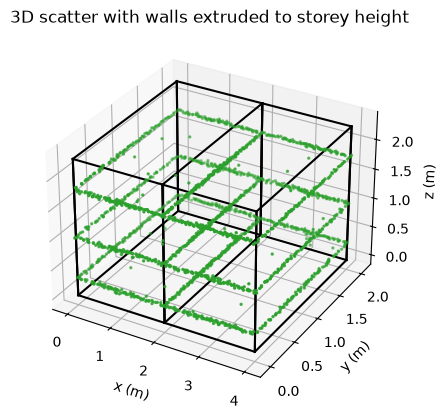

In [16]:
ax = point_cloud.plot(floor_plan, mode="3d")
ax.set_title("3D scatter with walls extruded to storey height")
plt.show()

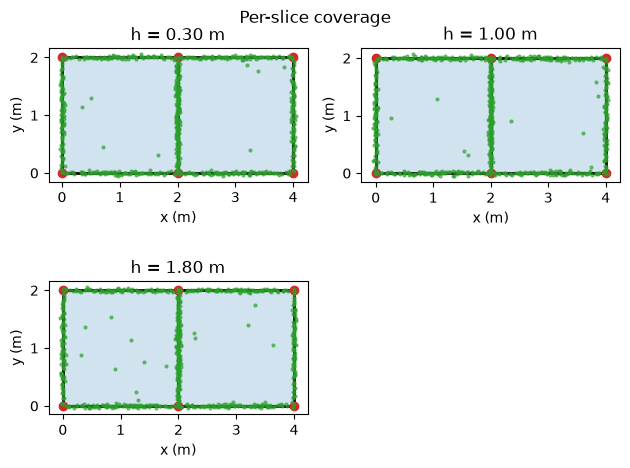

In [17]:
fig = point_cloud.plot(floor_plan, mode="slices", cols=2)
fig.suptitle("Per-slice coverage")
plt.show()

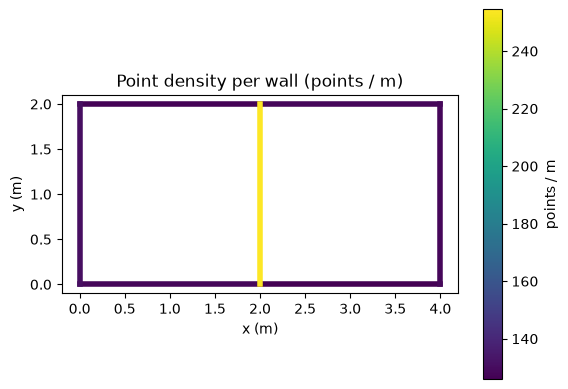

In [18]:
ax = point_cloud.plot(floor_plan, mode="coverage")
ax.set_title("Point density per wall (points / m)")
plt.show()

## Sim-to-real comparison and noise calibration

Stand in a "real" scan with a ground-truth noise model, start from a clearly wrong
guess, and use `calibrate_noise_model` to search a `NoiseModelPrior` for a better fit
by Chamfer distance.

In [19]:
true_noise_model = NoiseModel(
    range_sigma=0.03, angular_sigma=0.015, outlier_rate=0.05, missing_rate=0.1, height_sigma=0.02
)
real_point_cloud = simulate(
    floor_plan, scanner_positions, [1.0], true_noise_model, jax.random.PRNGKey(2), num_rays=360
)

guess_noise_model = NoiseModel(
    range_sigma=0.0, angular_sigma=0.0, outlier_rate=0.0, missing_rate=0.0, height_sigma=0.0
)
guess_point_cloud = simulate(
    floor_plan, scanner_positions, [1.0], guess_noise_model, jax.random.PRNGKey(3), num_rays=360
)

distance_before = calibration.chamfer_distance(guess_point_cloud, real_point_cloud)
print("Chamfer distance before calibration:", distance_before)

Chamfer distance before calibration: 0.031217120587825775


In [20]:
noise_prior = NoiseModelPrior(
    range_sigma=(0.0, 0.05),
    angular_sigma=(0.0, 0.03),
    outlier_rate=(0.0, 0.15),
    missing_rate=(0.0, 0.2),
    height_sigma=(0.0, 0.03),
)
calibrated_model = calibration.calibrate_noise_model(
    floor_plan,
    real_point_cloud,
    scanner_positions,
    noise_prior,
    jax.random.PRNGKey(4),
    num_candidates=40,
)
calibrated_point_cloud = simulate(
    floor_plan, scanner_positions, [1.0], calibrated_model, jax.random.PRNGKey(5), num_rays=360
)

distance_after = calibration.chamfer_distance(calibrated_point_cloud, real_point_cloud)
print("Calibrated noise model:", calibrated_model)
print(f"Chamfer distance: {distance_before:.4f} (before) -> {distance_after:.4f} (after)")

Calibrated noise model: NoiseModel(range_sigma=0.01458123978227377, angular_sigma=0.005319925490766764, outlier_rate=0.018137384206056595, missing_rate=0.033721137791872025, height_sigma=0.003285119542852044)
Chamfer distance: 0.0312 (before) -> 0.0285 (after)


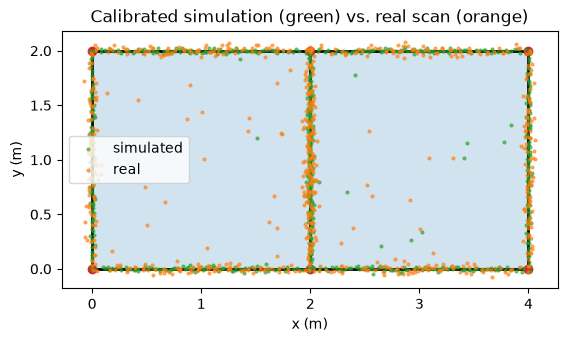

In [21]:
ax = sim_viz.plot_sim_to_real_overlay(calibrated_point_cloud, real_point_cloud, floor_plan)
ax.set_title("Calibrated simulation (green) vs. real scan (orange)")
plt.show()

This exercises the full Simulator component: scanner sweeps, hard/soft-occlusion ray casting, the noise pipeline, `simulate()`, visualisation, and calibration against a real scan. Next: `03_prior_samples.ipynb`.